# House Price Prediction - Linear Regression
**Dataset:** `HousePricePrediction.csv` (12-column subset of the Kaggle *House Prices* data)
**Task:** regression - predict `SalePrice`
**Covers:** missing values, one-hot encoding, train/test split, `LinearRegression`, R² / MAE / RMSE / MAPE, feature scaling, and **linear regression implemented from scratch with gradient descent**.

In [1]:
# Load Data
import pandas as pd
from sklearn.impute import SimpleImputer

df = pd.read_csv("../../data/HousePricePrediction.csv")

In [2]:
df.shape
df.head()
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 2919 entries, 0 to 2918
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Id            2919 non-null   int64  
 1   MSSubClass    2919 non-null   int64  
 2   MSZoning      2915 non-null   str    
 3   LotArea       2919 non-null   int64  
 4   LotConfig     2919 non-null   str    
 5   BldgType      2919 non-null   str    
 6   OverallCond   2919 non-null   int64  
 7   YearBuilt     2919 non-null   int64  
 8   YearRemodAdd  2919 non-null   int64  
 9   Exterior1st   2918 non-null   str    
 10  BsmtFinSF2    2918 non-null   float64
 11  TotalBsmtSF   2918 non-null   float64
 12  SalePrice     1460 non-null   float64
dtypes: float64(3), int64(6), str(4)
memory usage: 296.6 KB


,Id,MSSubClass,LotArea,OverallCond,YearBuilt,YearRemodAdd,BsmtFinSF2,TotalBsmtSF,SalePrice
count,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000,2919.000000,2918.000000,2918.000000,1460.000000
mean,1459.000000,57.137718,10168.114080,5.564577,1971.312778,1984.264474,49.582248,1051.777587,180921.195890
std,842.787043,42.517628,7886.996359,1.113131,30.291442,20.894344,169.205611,440.766258,79442.502883
min,0.000000,20.000000,1300.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,34900.000000
25%,729.500000,20.000000,7478.000000,5.000000,1953.500000,1965.000000,0.000000,793.000000,129975.000000
50%,1459.000000,50.000000,9453.000000,5.000000,1973.000000,1993.000000,0.000000,989.500000,163000.000000
75%,2188.500000,70.000000,11570.000000,6.000000,2001.000000,2004.000000,0.000000,1302.000000,214000.000000
max,2918.000000,190.000000,215245.000000,9.000000,2010.000000,2010.000000,1526.000000,6110.000000,755000.000000


## Data cleaning
Drop the `Id` column, remove rows without a target, then drop the few rows with other missing values.

In [3]:
# Data Preprocessing - Data cleaning

# Drop Id as it doesn't contribute in price
df.drop(['Id'],
             axis=1,
             inplace=True)

# Half of the rows (1,459 of 2,919) have no SalePrice - they are the unlabeled Kaggle test rows.
# Filling the target with its mean would invent fake labels, so those rows are dropped instead.
df = df.dropna(subset=["SalePrice"])

# Drop records with null values
df = df.dropna()

df.isnull().sum()
df.head()

,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF,SalePrice
0,60,RL,8450,Inside,1Fam,5,2003,2003,VinylSd,0.0,856.0,208500.0
1,20,RL,9600,FR2,1Fam,8,1976,1976,MetalSd,0.0,1262.0,181500.0
2,60,RL,11250,Inside,1Fam,5,2001,2002,VinylSd,0.0,920.0,223500.0
3,70,RL,9550,Corner,1Fam,5,1915,1970,Wd Sdng,0.0,756.0,140000.0
4,60,RL,14260,FR2,1Fam,5,2000,2000,VinylSd,0.0,1145.0,250000.0


## Encoding
One-hot encode the categorical columns (`drop_first=True` avoids the dummy-variable trap).

In [4]:
# Data Preprocessing - Encoding (Covered in Supervised ML Part2)
cols = ['MSZoning', 'LotConfig', 'BldgType', 'Exterior1st']
df = pd.get_dummies(df, columns=cols, drop_first=True)

In [5]:
# Train-Test Split
from sklearn.model_selection import train_test_split

X = df.drop(['SalePrice'], axis=1)
Y = df['SalePrice']

X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, random_state=0)

In [6]:
X_train.head()

,MSSubClass,LotArea,OverallCond,YearBuilt,YearRemodAdd,BsmtFinSF2,TotalBsmtSF,MSZoning_FV,MSZoning_RH,MSZoning_RL,...,Exterior1st_CemntBd,Exterior1st_HdBoard,Exterior1st_ImStucc,Exterior1st_MetalSd,Exterior1st_Plywood,Exterior1st_Stone,Exterior1st_Stucco,Exterior1st_VinylSd,Exterior1st_Wd Sdng,Exterior1st_WdShing
618,20,11694,5,2007,2007,0.0,1822.0,False,False,True,...,True,False,False,False,False,False,False,False,False,False
870,20,6600,5,1962,1962,0.0,894.0,False,False,True,...,False,False,False,True,False,False,False,False,False,False
92,30,13360,7,1921,2006,0.0,876.0,False,False,True,...,False,False,False,False,False,False,False,False,True,False
817,20,13265,5,2002,2002,0.0,1568.0,False,False,True,...,True,False,False,False,False,False,False,False,False,False
302,20,13704,5,2001,2002,0.0,1541.0,False,False,True,...,False,False,False,False,False,False,False,True,False,False


## Baseline: scikit-learn `LinearRegression`

In [7]:
# Train Linear Regression Model
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](33,)","[ 912.43, 0.84,5012.38,...,2496.16,3680.95,5910.4 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](33,)","['MSSubClass','LotArea','OverallCond',...,'Exterior1st_VinylSd', 'Exterior1st_Wd Sdng','Exterior1st_WdShing']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2.711e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,33
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,33


In [8]:
# Model Evaluation
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error
import numpy as np

y_pred = model.predict(X_test)

print("R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("MAPE:", mean_absolute_percentage_error(y_test, y_pred))

R2 Score: 0.43652920713688936
MAE: 34681.943259313026
RMSE: 62379.84253435378
MAPE: 0.20649186351548215


## Does feature scaling help?
Ordinary least squares has a closed-form solution, so standardising the features changes the coefficients but **not the predictions** - the metrics below should be identical to the baseline.

In [9]:
# Feature Scaling - to try & improve baseline performance
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LinearRegression()
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

print("R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("MAPE:", mean_absolute_percentage_error(y_test, y_pred))

# To get better results we can try some other regression model 
# & also use techniques like Bagging & Boosting (will cover later).

R2 Score: 0.4365292071368625
MAE: 34681.94325931286
RMSE: 62379.842534355266
MAPE: 0.20649186351548232


In [10]:
print(df["SalePrice"].mean())

180921.19589041095


## Linear regression from scratch (NumPy + gradient descent)
Minimise the mean squared error $J(w)=\frac{1}{m}\lVert Xw-y\rVert^2$ with the gradient $\nabla J = \frac{2}{m}X^T(Xw-y)$. Features are standardised so gradient descent converges. If it is correct, the metrics should match scikit-learn's closed-form solution.

In [11]:
# Linear Regression from scratch (without sklearn's LinearRegression)
# Reuses X_train, X_test, y_train and y_test from the train-test split above.

# Convert the split data to NumPy arrays and scale each feature manually.
X_train_manual = X_train.to_numpy(dtype=float)
X_test_manual = X_test.to_numpy(dtype=float)
y_train_manual = y_train.to_numpy(dtype=float)

feature_mean = X_train_manual.mean(axis=0)
feature_std = X_train_manual.std(axis=0)
feature_std[feature_std == 0] = 1  # Prevent division by zero for constant columns.

X_train_manual = (X_train_manual - feature_mean) / feature_std
X_test_manual = (X_test_manual - feature_mean) / feature_std

# Add a column of ones so the first weight acts as the intercept.
X_train_manual = np.c_[np.ones(X_train_manual.shape[0]), X_train_manual]
X_test_manual = np.c_[np.ones(X_test_manual.shape[0]), X_test_manual]

# Find the weights ourselves with gradient descent.
weights = np.zeros(X_train_manual.shape[1])
learning_rate = 0.01
epochs = 5000

for _ in range(epochs):
    predictions = X_train_manual @ weights
    errors = predictions - y_train_manual
    gradient = (2 / len(y_train_manual)) * (X_train_manual.T @ errors)
    weights -= learning_rate * gradient

# Predict and evaluate without using a sklearn regression model.
y_pred_manual = X_test_manual @ weights
residuals = y_test.to_numpy(dtype=float) - y_pred_manual

r2_manual = 1 - (np.sum(residuals ** 2) / np.sum((y_test - y_test.mean()) ** 2))
mae_manual = np.mean(np.abs(residuals))
rmse_manual = np.sqrt(np.mean(residuals ** 2))
mape_manual = np.mean(np.abs(residuals / y_test.to_numpy(dtype=float)))

print("Linear Regression from scratch (gradient descent)")
print("R2 Score:", r2_manual)
print("MAE:", mae_manual)
print("RMSE:", rmse_manual)
print("MAPE:", mape_manual)

Linear Regression from scratch (gradient descent)
R2 Score: 0.43665834185193453
MAE: 34664.40709543715
RMSE: 62372.694102816546
MAPE: 0.2063284308281274


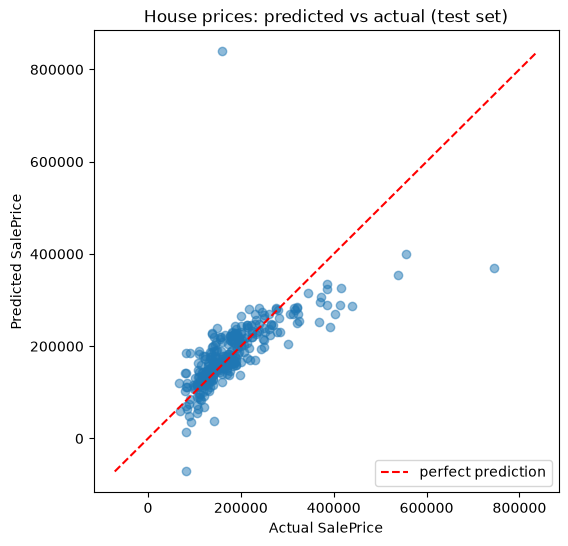

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_manual, alpha=0.5)
lims = [min(y_test.min(), y_pred_manual.min()), max(y_test.max(), y_pred_manual.max())]
plt.plot(lims, lims, "r--", label="perfect prediction")
plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")
plt.title("House prices: predicted vs actual (test set)")
plt.legend()
plt.show()